# 002 Easy — Direct B

`P_max, cN2_max, L_inj, dip_frac, x_of` → `E_med_MeV, dE_mad, q_end`

## Setup

In [2]:
from xgboost import XGBRegressor  # before torch (OpenMP clash on macOS)

import copy
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler

from pallas_score import normalised_to_physical, physical_to_normalised, score_submission
from physics_formulas import electrons_background, energy_gain_MeV, m3_to_cm3, species_B

torch.set_num_threads(1)

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"
TASK = "direct_B"
TARGETS = ['E_med_MeV', 'dE_mad', 'q_end']
FEATURES = ['P_max', 'cN2_max', 'L_inj', 'dip_frac', 'x_of']
EPOCHS = 300
BATCH = 32
XGB_TREES = 600
HIDDEN = [256, 512, 64]
LOSS = nn.HuberLoss()

B = pd.read_parquet(f"{PACK}/campaign_B.parquet", columns=["config", "injected"] + FEATURES + TARGETS)
data = B[B.injected].dropna()
test_inputs = pd.read_parquet(f"{PACK}/test_direct.parquet")


def gain_at_plasma_end(frame):
    out = np.zeros(len(frame))
    for i, row in enumerate(frame.itertuples()):
        z = np.linspace(0, (row.L_inj + 3.2) * 1e3, 300)
        n_He, n_N = species_B(z, row.P_max, row.cN2_max, row.L_inj, row.dip_frac)
        n_e = m3_to_cm3(electrons_background(n_He, n_N))
        out[i] = energy_gain_MeV(z, n_e, eta=0.27)[-1]
    return out


def features(frame):
    X = frame[FEATURES].copy()
    X["n_e"] = X.P_max * (1 - 0.3 * X.cN2_max)
    X["n_N2"] = X.P_max * X.cN2_max
    X["L_plasma"] = X.L_inj + 3.2
    X["E0_L"] = np.sqrt(X.n_e) * X.L_plasma
    X["dip_abs"] = X.dip_frac * X.P_max
    X["gain"] = gain_at_plasma_end(frame)
    return X.to_numpy()


def targets(frame):
    columns = []
    for t in TARGETS:
        columns.append(physical_to_normalised(t, frame[t]))
    return np.column_stack(columns)


def physical(pred):
    out = pd.DataFrame()
    for i, t in enumerate(TARGETS):
        out[t] = normalised_to_physical(t, pred[:, i])
    return out


def score(pred, frame):
    pred = physical(pred)
    pred.insert(0, "config", frame.config.to_numpy())
    return score_submission(pred, frame[["config"] + TARGETS])


train, test = train_test_split(data, test_size=0.2, random_state=0)
print(f"{len(data):,} rows, {len(train):,} train / {len(test):,} test")

2,882 rows, 2,305 train / 577 test


## Random forest

In [3]:
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
rf.fit(features(train), targets(train))
score(rf.predict(features(test)), test)

{'E_med_MeV': 0.958689389466286,
 'dE_mad': 0.743420843577618,
 'q_end': 0.8561515404569454,
 'mean': 0.8527539245002832,
 'n_rows': 577}

## XGBoost

In [4]:
xgb = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
xgb.fit(features(train), targets(train))
score(xgb.predict(features(test)), test)

{'E_med_MeV': 0.9724686586045509,
 'dE_mad': 0.8258388182587032,
 'q_end': 0.9525276596981338,
 'mean': 0.9169450455204626,
 'n_rows': 577}

## MLP

In [5]:
def build_mlp(n_inputs):
    return nn.Sequential(
        nn.Linear(n_inputs, HIDDEN[0]), nn.ReLU(),
        nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(),
        nn.Linear(HIDDEN[1], HIDDEN[2]), nn.ReLU(),
        nn.Linear(HIDDEN[2], len(TARGETS)),
    )


def fit_model(train, val, seed, build=build_mlp, epochs=EPOCHS):
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(features(train))
    y_mean = targets(train).mean(0)
    y_std = targets(train).std(0)

    X = torch.tensor(scaler.transform(features(train)), dtype=torch.float32)
    y = torch.tensor((targets(train) - y_mean) / y_std, dtype=torch.float32)
    if val is not None:
        X_val = torch.tensor(scaler.transform(features(val)), dtype=torch.float32)
        y_val = torch.tensor((targets(val) - y_mean) / y_std, dtype=torch.float32)

    net = build(X.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    val_loss = []
    best_net = net
    for epoch in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = LOSS(net(X[idx]), y[idx])
            loss.backward()
            opt.step()
        sched.step()
        if val is not None:
            with torch.no_grad():
                val_loss.append(LOSS(net(X_val), y_val).item())
            if val_loss[-1] == min(val_loss):
                best_net = copy.deepcopy(net)

    return {"net": best_net, "scaler": scaler, "y_mean": y_mean, "y_std": y_std, "val_loss": val_loss}


def fit_mlp(train, val, seed):
    return fit_model(train, val, seed)


def predict_mlp(model, X):
    X = torch.tensor(model["scaler"].transform(X), dtype=torch.float32)
    with torch.no_grad():
        out = model["net"](X).numpy()
    return out * model["y_std"] + model["y_mean"]


def predict_ensemble(models, X):
    preds = []
    for model in models:
        preds.append(predict_mlp(model, X))
    return np.mean(preds, axis=0)


mlp = fit_mlp(train, test, seed=0)
print(f"best val loss {min(mlp['val_loss']):.4f} at epoch {np.argmin(mlp['val_loss']) + 1}")
score(predict_mlp(mlp, features(test)), test)

best val loss 0.0028 at epoch 153


{'E_med_MeV': 0.9982272467229916,
 'dE_mad': 0.9855453578703094,
 'q_end': 0.9992651172500765,
 'mean': 0.9943459072811258,
 'n_rows': 577}

## MLP ensemble

Three seeds averaged.

In [6]:
ensemble = [mlp]
for seed in (1, 2):
    ensemble.append(fit_mlp(train, test, seed))
score(predict_ensemble(ensemble, features(test)), test)

{'E_med_MeV': 0.9985803574303533,
 'dE_mad': 0.9875789556693814,
 'q_end': 0.9994662067936497,
 'mean': 0.9952085066311281,
 'n_rows': 577}

## Cross validation

In [7]:
rows = []
curves = []
for k, (train_idx, val_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(data)):
    tr = data.iloc[train_idx]
    va = data.iloc[val_idx]

    rf_k = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0)
    rf_k.fit(features(tr), targets(tr))
    xgb_k = MultiOutputRegressor(XGBRegressor(n_estimators=XGB_TREES, learning_rate=0.05, max_depth=7,
                                              subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0))
    xgb_k.fit(features(tr), targets(tr))
    mlp_k = fit_mlp(tr, va, seed=k)
    curves.append(mlp_k["val_loss"])

    rows.append({
        "rf": score(rf_k.predict(features(va)), va)["mean"],
        "xgb": score(xgb_k.predict(features(va)), va)["mean"],
        "mlp": score(predict_mlp(mlp_k, features(va)), va)["mean"],
    })
    print(f"fold {k}  mlp best val loss {min(mlp_k['val_loss']):.4f} at epoch {np.argmin(mlp_k['val_loss']) + 1}")

cv = pd.DataFrame(rows)
cv.loc["mean"] = cv.mean()
cv.loc["std"] = cv.iloc[:-1].std()
cv.round(4)

fold 0  mlp best val loss 0.0027 at epoch 182
fold 1  mlp best val loss 0.0030 at epoch 158
fold 2  mlp best val loss 0.0031 at epoch 99
fold 3  mlp best val loss 0.0030 at epoch 99
fold 4  mlp best val loss 0.0031 at epoch 115


,rf,xgb,mlp
0,0.8557,0.9187,0.9944
1,0.8480,0.9179,0.9941
2,0.8664,0.9347,0.9945
3,0.8668,0.9330,0.9940
4,0.8434,0.9195,0.9929
mean,0.8561,0.9248,0.9940
std,0.0106,0.0083,0.0007


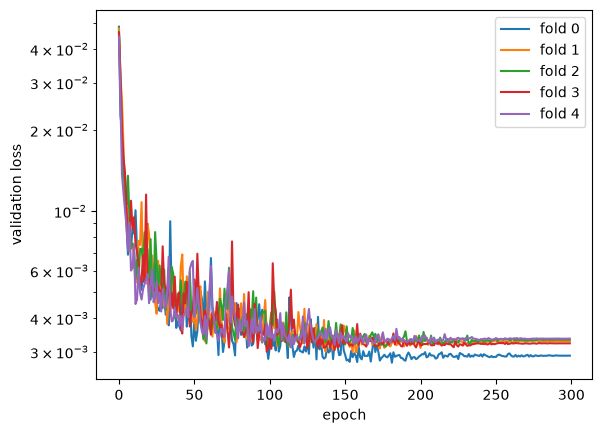

In [11]:
for k, curve in enumerate(curves):
    plt.plot(curve, label=f"fold {k}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

## Final model on every row

Trained on all injected rows for the submission.

In [12]:
final = []
for seed in (0, 1, 2):
    final.append(fit_model(data, None, seed))
print("trained on all", len(data), "injected rows")

trained on all 2882 injected rows


## The trajectory model read at its end

The Direct B targets are the trajectory values at the last position, and the hidden test configs are the same, so the trajectory ensemble is also a Direct B model. Submission = average of both.

In [13]:
TRAJ_TARGETS = ["E_MeV", "q_pC", "dE_pct", "emit_um", "div_mrad", "sigz_um"]
TRAJ_FEATURES = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "z_mm", "dz", "in_plasma", "n_e", "n_N2", "gain"]


class ResidualMLP(nn.Module):
    def __init__(self, n_inputs, width=512, n_blocks=3):
        super().__init__()
        self.inp = nn.Linear(n_inputs, width)
        self.blocks = nn.ModuleList()
        for _ in range(n_blocks):
            self.blocks.append(nn.Sequential(nn.Linear(width, width), nn.ReLU(), nn.Linear(width, width)))
        self.out = nn.Linear(width, len(TRAJ_TARGETS))

    def forward(self, x):
        h = torch.relu(self.inp(x))
        for block in self.blocks:
            h = torch.relu(h + block(h))
        return self.out(h)


def trajectory_features(frame):
    frame = frame.copy()
    frame["dz"] = frame.z_mm - (frame.L_inj + 3.2)
    frame["in_plasma"] = (frame.dz <= 0).astype(float)
    frame["n_e"] = frame.P_max * (1 - 0.3 * frame.cN2_max)
    frame["n_N2"] = frame.P_max * frame.cN2_max
    frame["gain"] = 0.0
    for config, rows in frame.groupby("config"):
        row = rows.iloc[0]
        z = np.linspace(0, (row.L_inj + 3.2) * 1e3, 500)
        n_He, n_N = species_B(z, row.P_max, row.cN2_max, row.L_inj, row.dip_frac)
        n_e = m3_to_cm3(electrons_background(n_He, n_N))
        gain = energy_gain_MeV(z, n_e, eta=0.27)
        frame.loc[rows.index, "gain"] = np.interp(rows.z_mm * 1e3, z, gain)
    return frame[TRAJ_FEATURES].to_numpy()


def trajectory_at_end(frame):
    X = trajectory_features(frame)
    preds = []
    for seed in (0, 1, 2):
        scaler = np.load(f"models/lsr_trajectory_mlp/scaler_seed{seed}.npz")
        net = ResidualMLP(X.shape[1])
        net.load_state_dict(torch.load(f"models/lsr_trajectory_mlp/model_seed{seed}.pt"))
        X_t = torch.tensor((X - scaler["x_mean"]) / scaler["x_std"], dtype=torch.float32)
        with torch.no_grad():
            preds.append(net(X_t).numpy() * scaler["y_std"] + scaler["y_mean"])
    pred = np.mean(preds, axis=0)
    return np.column_stack([pred[:, 0], pred[:, 2], pred[:, 1]])


test_trajectory = pd.read_parquet(f"{PACK}/test_trajectory.parquet")
end_rows = test_trajectory[test_trajectory.z_mm == test_trajectory.z_mm.max()].sort_values("config")
test_inputs = test_inputs.sort_values("config").reset_index(drop=True)
print("same configurations:", list(end_rows.config) == list(test_inputs.config))

from_scalar = predict_ensemble(final, features(test_inputs))
if os.path.exists("models/lsr_trajectory_mlp/model_seed0.pt"):
    from_trajectory = trajectory_at_end(end_rows)
    blend = 0.5 * from_scalar + 0.5 * from_trajectory
    print(pd.DataFrame({"scalar": physical(from_scalar).mean(), "trajectory end": physical(from_trajectory).mean()}).round(4))
else:
    print("trajectory models not found (run 004 first), using the scalar ensemble alone")
    blend = from_scalar

same configurations: True
trajectory models not found (run 004 first), using the scalar ensemble alone


## Submission

In [14]:
submission = physical(blend)
submission.insert(0, "config", test_inputs.config.to_numpy())
submission.to_csv("submission_direct.csv", index=False)
print(f"wrote submission_direct.csv ({len(submission):,} rows)")

wrote submission_direct.csv (357 rows)


## Save for the Hopsworks registry

In [15]:
name = f"lsr_{TASK}_mlp"
path = f"models/{name}"
os.makedirs(path, exist_ok=True)
for seed, model in enumerate(final):
    torch.save(model["net"].state_dict(), f"{path}/model_seed{seed}.pt")
    np.savez(f"{path}/scaler_seed{seed}.npz", x_mean=model["scaler"].mean_, x_std=model["scaler"].scale_,
             y_mean=model["y_mean"], y_std=model["y_std"])

scores = score(predict_ensemble(ensemble, features(test)), test)
metrics = {}
for t in TARGETS:
    metrics[f"holdout_r2_{t}"] = round(scores[t], 4)
metrics["holdout_mean_r2"] = round(scores["mean"], 4)
metrics["cv_mean_r2"] = round(float(cv.loc["mean", "mlp"]), 4)

json.dump({"task": TASK, "model": "mlp", "features": FEATURES, "targets": TARGETS, "metrics": metrics},
          open(f"{path}/meta.json", "w"), indent=1)
metrics

{'holdout_r2_E_med_MeV': 0.9986,
 'holdout_r2_dE_mad': 0.9876,
 'holdout_r2_q_end': 0.9995,
 'holdout_mean_r2': 0.9952,
 'cv_mean_r2': 0.994}

## Comparison

In [16]:
table = pd.DataFrame({
    "rf": score(rf.predict(features(test)), test),
    "xgb": score(xgb.predict(features(test)), test),
    "mlp": score(predict_mlp(mlp, features(test)), test),
    "ensemble": score(predict_ensemble(ensemble, features(test)), test),
    "linear baseline (bar)": {"E_med_MeV": 0.940, "dE_mad": 0.261, "q_end": 0.814, "mean": 0.672},
    "internal model": {"E_med_MeV": 0.9744, "dE_mad": 0.8036, "q_end": 0.9420, "mean": 0.9067},
})
table.T[TARGETS + ["mean"]].round(3)

,E_med_MeV,dE_mad,q_end,mean
rf,0.959,0.743,0.856,0.853
xgb,0.972,0.826,0.953,0.917
mlp,0.998,0.986,0.999,0.994
ensemble,0.999,0.988,0.999,0.995
linear baseline (bar),0.940,0.261,0.814,0.672
internal model,0.974,0.804,0.942,0.907
